This file generates embeddings for half completed and fully complete drawings. The goal is to see how drawing similarity to adults changes over time. 

Plan:
1. Collect stroke PNGs from stroke dataset (_1, _2... _N)
2. Choose halfway point (half_k = ceil(N/2))
3. Composite strokes into half complete image (1... half_k) and full complete image (1... N) and save 50% images
4. Compute CLIP embeddings for 50% images
5. Save metadata: participant_id, category, age_months, half_complete_embedding, 

In [ ]:
#TODO: right now filepath for the final df is ../data/.... but want to make this labs/vislearnlab... etc. so it is not breakable if project were to be reorganized

In [22]:
#Import packages
import math
import json
from pathlib import Path
import re

import numpy as np
import pandas as pd
import torch
from PIL import Image
import open_clip


In [23]:
#Config
STROKES_CSV = "../data/raw/mongo_output/AllDescriptives_strokes_png_final_birch_run_v1.csv"

HALF_IMG_DIR = Path("../data/raw/half_time")
OUT_CSV = "../data/embeddings/half_time_sketch_embeddings/half_time_clip_embeddings.csv"

BASE_DIR = None 


In [24]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EMBED_BATCH_SIZE = 64

In [25]:
MODEL_NAME = "ViT-B-32"
PRETRAINED = "openai"

Helper functions

In [26]:
def resolve_path(p: str) -> Path:
    pth = Path(p)
    if pth.is_absolute():
        return pth
    return (BASE_DIR / pth) if BASE_DIR is not None else pth

In [27]:
def safe_name(x: str) -> str:
    """Make safe filename components."""
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(x))

In [28]:
def load_rgba(path: Path) -> Image.Image:
    return Image.open(path).convert("RGBA")

In [29]:
def composite_strokes(stroke_paths: list[Path]) -> Image.Image:
    base = load_rgba(stroke_paths[0])
    for p in stroke_paths[1:]:
        base = Image.alpha_composite(base, load_rgba(p))
    return base


In [30]:
def make_half_image(g: pd.DataFrame) -> tuple[Image.Image, int, int, list[str]]:
    """
    Given one participant × category group, return:
    half_img, N, half_k, missing_files
    """
    g = g.sort_values("stroke_num")
    paths = [resolve_path(f) for f in g["filename"].tolist()]

    existing, missing = [], []
    for p in paths:
        (existing if p.exists() else missing).append(p)

    if len(existing) == 0:
        raise FileNotFoundError("No stroke PNGs found for this drawing.")

    N = len(existing)
    half_k = int(math.ceil(N / 2))

    half_img = composite_strokes(existing[:half_k])
    return half_img, N, half_k, [str(p) for p in missing]


In [31]:
def load_clip(model_name=MODEL_NAME, pretrained=PRETRAINED, device=DEVICE):
    model, _, preprocess = open_clip.create_model_and_transforms(
        model_name,
        pretrained=pretrained
    )
    return model.to(device), preprocess

In [32]:
@torch.no_grad()
def embed_images(model, preprocess, images: list[Image.Image], device=DEVICE, batch_size=64) -> np.ndarray:
    """
    Returns L2-normalized embeddings with shape: n_images × embedding_dim
    """
    model.eval()
    outs = []

    for i in tqdm(range(0, len(images), batch_size), desc="Embedding batches", leave=False):
        batch_imgs = images[i:i + batch_size]
        batch = torch.stack([
            preprocess(im.convert("RGB")) for im in batch_imgs
        ]).to(device)

        feats = model.encode_image(batch)

        # L2 normalize
        feats = feats / feats.norm(dim=-1, keepdim=True)

        outs.append(feats.cpu().numpy())

    return np.vstack(outs)



In [33]:
def vec_to_json(v: np.ndarray) -> str:
    return json.dumps(v.astype(np.float32).tolist())

In [34]:
# Pipeline steps
def load_strokes(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)

    df["stroke_num"] = pd.to_numeric(df["stroke_num"], errors="coerce")

    if df["stroke_num"].isna().any():
        raise ValueError("stroke_num has non-numeric values; fix before running.")

    return df

In [35]:
def build_and_save_half_images(strokes_df: pd.DataFrame):
    """
    Builds 50% composite images and saves PNG files to HALF_IMG_DIR.

    Returns:
    - half_imgs
    - meta_rows
    - error_rows
    """
    HALF_IMG_DIR.mkdir(parents=True, exist_ok=True)

    half_imgs = []
    meta_rows = []
    error_rows = []

    grouped = list(strokes_df.groupby(["participant_id", "category"], sort=False))
    print(f"Drawings (participant × category): {len(grouped)}")

    for (participant_id, category), g in tqdm(grouped, desc="Saving 50% drawings"):
        age_months = g["age_months"].dropna().iloc[0] if g["age_months"].notna().any() else np.nan

        try:
            half_img, N, half_k, missing_files = make_half_image(g)

            category_dir = HALF_IMG_DIR / safe_name(category)
            category_dir.mkdir(parents=True, exist_ok=True)

            out_filename = f"{safe_name(participant_id)}_{safe_name(category)}_half.png"
            out_path = category_dir / out_filename

            half_img.convert("RGB").save(out_path)

            half_imgs.append(half_img)

            meta_rows.append({
                "participant_id": participant_id,
                "category": category,
                "age_months": age_months,
                "half_image_path": str(out_path),
                "n_strokes_found": N,
                "half_k": half_k,
                "missing_files": json.dumps(missing_files),
            })

        except Exception as e:
            error_rows.append({
                "participant_id": participant_id,
                "category": category,
                "age_months": age_months,
                "half_image_path": None,
                "n_strokes_found": 0,
                "half_k": None,
                "missing_files": None,
                "half_time_embedding": None,
                "error": repr(e),
            })

    return half_imgs, meta_rows, error_rows



In [36]:
def assemble_output(meta_rows, half_embs):
    rows = []
#Adding all metadata rows here but can also choose to only add a subset of metadata columns if desired
    for m, emb in zip(meta_rows, half_embs):
        row = dict(m)  # copy full metadata
        row["half_time_embedding"] = vec_to_json(emb)
        rows.append(row)

    return pd.DataFrame(rows)

Main

In [37]:
from tqdm import tqdm

In [38]:
def main():
    strokes_df = load_strokes(STROKES_CSV)

    model, preprocess = load_clip()

    half_imgs, meta_rows, error_rows = build_and_save_half_images(strokes_df)

    half_embs = embed_images(
        model,
        preprocess,
        half_imgs,
        batch_size=EMBED_BATCH_SIZE
    )

    out_df = assemble_output(meta_rows, half_embs)
    err_df = pd.DataFrame(error_rows)

    final_df = pd.concat([out_df, err_df], ignore_index=True)

    Path(OUT_CSV).parent.mkdir(parents=True, exist_ok=True)
    final_df.to_csv(OUT_CSV, index=False)

    print(f"Saved embeddings: {OUT_CSV}")
    print(f"Saved 50% images to: {HALF_IMG_DIR}")
    print(f"OK: {len(out_df)} | Errors: {len(err_df)}")



In [39]:
if __name__ == "__main__":
    main()

/Scratch/nsahrling/miniconda3/lib/python3.13/site-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Drawings (participant × category): 1355


Saving 50% drawings: 100%|██████████| 1355/1355 [01:00<00:00, 22.51it/s]


Saved embeddings: ../data/embeddings/half_time_sketch_embeddings/half_time_clip_embeddings.csv
Saved 50% images to: ../data/raw/half_time
OK: 1354 | Errors: 1


In [40]:
#Let's check that the 50% stroke png files look good in 10-20 examples

In [41]:
idx = 0  # try a few indices: 0, 5, 20, etc.
img = half_imgs[idx]

# RGBA channel ranges
print("mode:", img.mode, "size:", img.size)
print("bbox (non-zero region):", img.getbbox())

# alpha extrema tells you if anything is visible (0..255)
alpha = img.split()[-1]
print("alpha min/max:", alpha.getextrema())

NameError: name 'half_imgs' is not defined

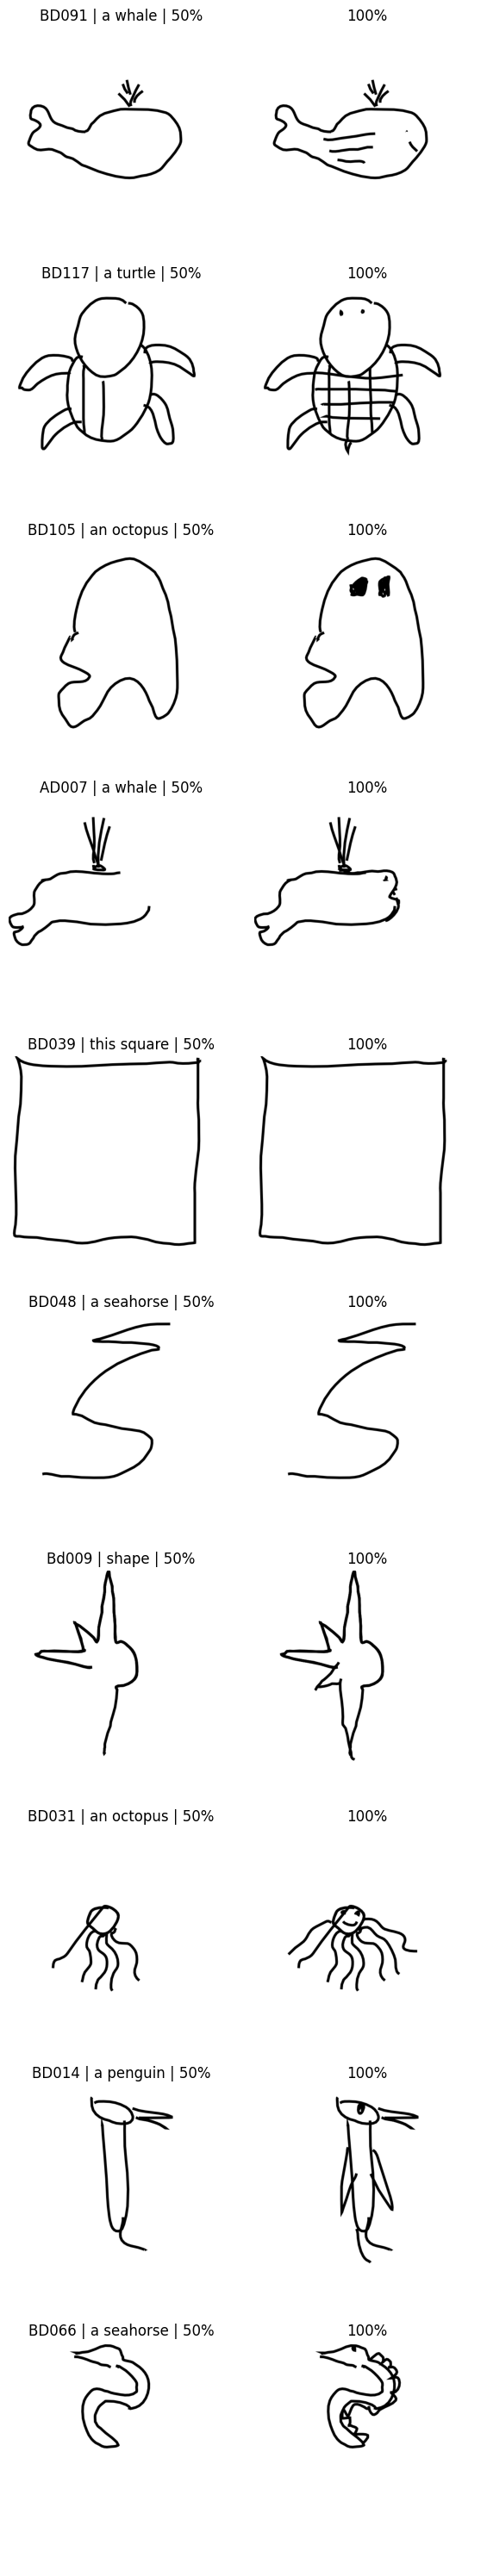

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(40)

# reload strokes file
strokes_df = pd.read_csv(STROKES_CSV)

# group drawings
groups = list(strokes_df.groupby(["participant_id","category"]))

# sample 10 drawings
sample_groups = random.sample(groups, 10)

fig, axes = plt.subplots(10,2, figsize=(6,30))

for i, ((pid, cat), g) in enumerate(sample_groups):

    g = g.sort_values("stroke_num")
    paths = [resolve_path(f) for f in g["filename"]]

    existing = [p for p in paths if p.exists()]
    N = len(existing)
    half_k = int(np.ceil(N/2))

    # composite half
    half = composite_strokes(existing[:half_k])
    full = composite_strokes(existing)

    # render on white background so transparency is visible
    bg = Image.new("RGBA", half.size, (255,255,255,255))
    half_vis = Image.alpha_composite(bg, half).convert("RGB")
    full_vis = Image.alpha_composite(bg, full).convert("RGB")

    axes[i,0].imshow(half_vis)
    axes[i,0].set_title(f"{pid} | {cat} | 50%")
    axes[i,0].axis("off")

    axes[i,1].imshow(full_vis)
    axes[i,1].set_title("100%")
    axes[i,1].axis("off")

plt.tight_layout()
plt.savefig("../figures/cds_time.pdf")
plt.show()